# The motor decoder's error on 1-object stimuli, around the ring → `decoder_1obj_error.pdf`

The decoder of [`../figure_3/motor_decoding/decoder_v2.ipynb`](../figure_3/motor_decoding/decoder_v2.ipynb):
the same 2 monkeys × 5 bootstrap draws of 100 neurons, the same joint fit, the same read-out. Its
hyperparameters are read from that notebook's CONFIG cell, and the fitted decoders are cached in
`cache/figures/supp_figure_4/decoders/` by `decoder_cache.py`. The fit reports match `decoder_v2`'s line for line, and
nothing here refits.

For a single object at angle θ, the error is the signed distance from θ to the decode's
**nearest local maximum**, using `decoder_v2`'s peak criterion (`PEAK_MIN_HEIGHT_FRAC`). Positive
means the decode sits counter-clockwise of the object. Two inputs are computed:
* **mean response**: the population's expected response at θ, which is what `decoder_v2`'s ring
  panels decode;
* **single trials**: one simulated trial per neuron and replica, which is what the decoder is fit on.

**The figure**, one ring per monkey: the outer ring carries `N_TARGETS` dots at the target angles,
coloured by hue around the circle. The inner ring carries a cross of the same colour at each
target's decoded angle: the target plus its error, averaged over the 5 draws (`DECODED` picks mean
response or single trials). A cross directly inside its dot means no error. The single-trial
spread is printed above the figure rather than drawn.

Not cross-validated: the decoder is fit and evaluated on the same 1-object trials. That cannot
move the mean error, which the replica symmetry pins at zero, but the single-trial SD is likely
optimistic.

**Expect it to be flat, by construction.** Every neuron enters the decoder as `NUM_REPLICAS` = 64
rotated copies, each also mirrored, and the decoder's weights rotate with them. Rotating the object
by 360°/64 = 5.625° therefore only permutes the population's inputs. The decoder's 1-object error
can vary with θ only with that 5.625° period, never with the object's place on the ring. The
figure measures how large that ripple is and how much single trials scatter around it.

`PEAK_REFINE`: the decode is evaluated on a 2° grid, so `decoder_v2`'s convention (`False`) reports
a maximum only to the nearest grid point, and every mean-response error comes out as 0 or ±1°.
`True` places the maximum between grid points (the vertex of a parabola through the three grid
points around it), which is what lets the ripple show.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
common.set_style()
import decoder_cache as dc

FIGSIZE = (5.5, 3.2)          # two ring panels side by side, one per monkey
OUTPUT = 'decoder_1obj_error.pdf'

THETA_STEP_DEG = 1.0          # object angles evaluated, every this many degrees
N_TRIAL_SAMPLES = 20          # single-trial decodes per angle per draw (~40 s per draw at 20; cached
                              #   per sample, so raising it computes only the new ones)
SAMPLE_SEED = 0
PEAK_REFINE = True            # sub-grid peak location; False = decoder_v2's 2-deg grid convention

N_TARGETS = 12                # target angles drawn, evenly spaced from 0 deg; 360 / N_TARGETS must be
                              #   a multiple of THETA_STEP_DEG (the sweep's resolution)
DECODED = 'mean'              # 'mean': decode of the expected response; 'trial': circular mean of
                              #   the single-trial decodes. Either way averaged over the 5 draws.
R_TARGET = 1.0                # outer ring (targets) ...
R_DECODED = 0.72              # ... and inner ring (decoded positions), in ring radii
DOT_SIZE = 110                # target dot area (pt^2)
CROSS_SIZE = 11               # decoded-cross size (pt) ...
CROSS_EDGE = 2.2              # ... and line width
RING_COLOR = '0.8'            # the two guide circles
FIX_SIZE = 10                 # fixation cross at the ring's centre (pt) — as in decoder_v2's
FIX_LINEWIDTH = 1.6           #   ring panels, scaled up because these rings are larger


In [2]:
cfg = dc.decoder_config()
print({k: cfg[k] for k in dc.FIT_KEYS})
dc.ensure_all(cfg)            # fits nothing if the decoder cache is current

sweeps = pd.concat([dc.error_sweep(s, b, THETA_STEP_DEG, N_TRIAL_SAMPLES, SAMPLE_SEED,
                                   PEAK_REFINE, cfg)
                    for s in cfg['SUBJECTS'] for b in range(cfg['N_BOOTSTRAPS'])],
                   ignore_index=True)
for s in cfg['SUBJECTS']:
    g = sweeps[sweeps['subject'] == s]
    m, t = g[g['kind'] == 'mean']['err_deg'], g[g['kind'] == 'trial']['err_deg']
    print(f'{dc.SUBJECT_TITLE[s]}: mean response  error {m.mean():+.2f}° (range {m.min():+.2f} to '
          f'{m.max():+.2f}°) | single trials {t.mean():+.2f} ± {t.std():.2f}° (SD), '
          f'{int(t.isna().sum())} with no maximum, n = {len(t)}')


{'NUM_NEURONS': 100, 'SEED': 0, 'NUM_REPLICAS': 64, 'SAMPLE_SIGMA_DEG': 15.0, 'LOBE_WIDTH_DEG': 30.0, 'FIT_N_SAMPLES': 1000, 'FIT_K_MAX': 6, 'FIT_PHASES': True, 'FIT_ITERS': 3, 'EXCLUSION': 'config'}
Monkey P: mean response  error +0.00° (range -0.44 to +0.44°) | single trials -0.01 ± 1.83° (SD), 0 with no maximum, n = 36000
Monkey E: mean response  error +0.00° (range -1.21 to +1.21°) | single trials -0.01 ± 1.85° (SD), 0 with no maximum, n = 36000


Monkey P: decoded minus target at the 12 targets: -0.09 to +0.09°
    SD of response error — single trials: 1.83° (n = 36000); mean response: 0.17° (n = 1800)
Monkey E: decoded minus target at the 12 targets: -0.34 to +0.34°
    SD of response error — single trials: 1.85° (n = 36000); mean response: 0.37° (n = 1800)


saved decoder_1obj_error.pdf


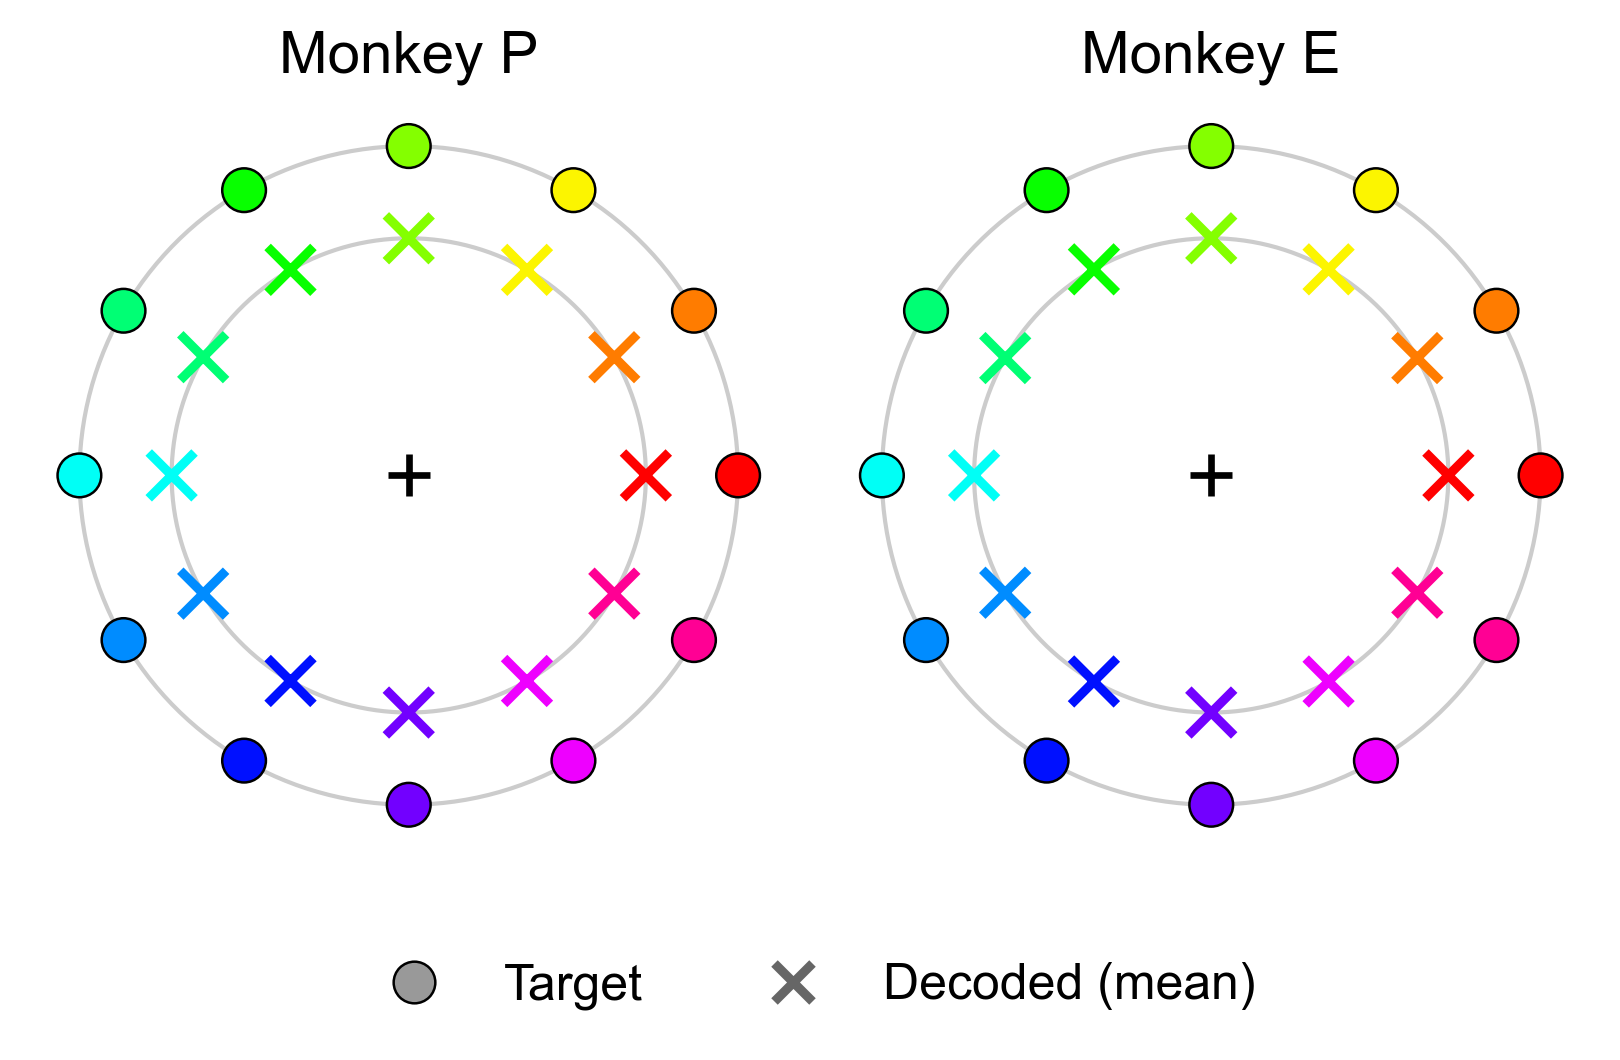

In [3]:
step = 360.0 / N_TARGETS
assert abs(step / THETA_STEP_DEG - round(step / THETA_STEP_DEG)) < 1e-9, \
    'N_TARGETS must put every target on the sweep grid'
targets_deg = np.arange(N_TARGETS) * step
colors = plt.cm.hsv(targets_deg / 360.0)        # hue = angle around the ring

fig, axes = plt.subplots(1, len(cfg['SUBJECTS']), figsize=FIGSIZE)
for ax, s in zip(np.atleast_1d(axes), cfg['SUBJECTS']):
    g = sweeps[(sweeps['subject'] == s) & (sweeps['kind'] == DECODED)]
    g = g[np.isclose(g['theta_deg'].to_numpy()[:, None], targets_deg[None, :]).any(axis=1)]
    # Circular mean of the decoded angle over draws (and samples), per target.
    dec = g.assign(z=np.exp(1j * np.radians(g['theta_deg'] + g['err_deg']))) \
           .groupby('theta_deg')['z'].mean()
    dec_rad = np.angle(dec.reindex(targets_deg).to_numpy())
    err = (np.degrees(dec_rad) - targets_deg + 180) % 360 - 180
    print(f'{dc.SUBJECT_TITLE[s]}: decoded minus target at the {N_TARGETS} targets: '
          f'{err.min():+.2f} to {err.max():+.2f}°')
    # The SD of the response error, over every angle of the sweep (not only the drawn targets).
    a = sweeps[sweeps['subject'] == s]
    e_trial = a.loc[a['kind'] == 'trial', 'err_deg']
    e_mean = a.loc[a['kind'] == 'mean', 'err_deg']
    print(f'    SD of response error — single trials: {e_trial.std():.2f}° '
          f'(n = {e_trial.notna().sum()}); mean response: {e_mean.std():.2f}° '
          f'(n = {e_mean.notna().sum()})')

    phi = np.linspace(0, 2 * np.pi, 361)
    for r in (R_TARGET, R_DECODED):
        ax.plot(r * np.cos(phi), r * np.sin(phi), color=RING_COLOR, lw=1.0, zorder=1)
    t = np.radians(targets_deg)
    ax.scatter(R_TARGET * np.cos(t), R_TARGET * np.sin(t), s=DOT_SIZE, c=colors,
               edgecolors='k', linewidths=0.6, zorder=3, label='Target')
    ax.scatter(R_DECODED * np.cos(dec_rad), R_DECODED * np.sin(dec_rad), s=CROSS_SIZE ** 2,
               c=colors, marker='x', linewidths=CROSS_EDGE, zorder=3, label='Decoded')
    ax.plot([0], [0], marker='+', color='k', markersize=FIX_SIZE,
            markeredgewidth=FIX_LINEWIDTH, zorder=4)       # fixation cross
    ax.set_title(dc.SUBJECT_TITLE[s])
    lim = R_TARGET * 1.15
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.axis('off')

# Below the panels, so it covers no data. Neutral swatches: the colour of a mark is its angle.
from matplotlib.lines import Line2D
handles = [Line2D([], [], ls='none', marker='o', markersize=10, markerfacecolor='0.6',
                  markeredgecolor='k', markeredgewidth=0.6, label='Target'),
           Line2D([], [], ls='none', marker='x', markersize=9, markeredgecolor='0.4',
                  markeredgewidth=CROSS_EDGE, label=f'Decoded ({DECODED})')]
fig.tight_layout()
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.04), ncol=2,
           frameon=False)
common.save(fig, OUTPUT)
plt.show()
